# 02 · Passive balloons: gap-hours per launch

**The question:** per launch, how many hours does a balloon spend in "the gap" (the poorly observed North Atlantic and Arctic)?

**The setup:**
- One virtual balloon launched every day at 00 UTC, 1 Dec to end of Feb.
- 9 winters, 2013/14 to 2021/22.
- Five sites, three heights.
- Each balloon is **passive**: it stays at one pressure level and goes wherever the wind takes it, for 21 days.

The functions are the ones built and tested in notebook 01. They're stored once in `balloon.py`.

**Choices** (see `decisions.md`):
- **The gap:** more than 500 km from any active radiosonde station, inside 45 to 90°N and 70°W to 30°E. We also show 300 and 800 km as checks.
- **Horizons:** 7 and 21 days.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import balloon as b      # our shared functions (notebook 01 explains each one)

SITES = {                               # name: (lat, lon)
    "Egilsstaðir":  (65.28, -14.40),
    "Keflavík":     (63.97, -22.60),
    "New York*":    (40.71, -74.01),    # *stand-in: WindBorne's NY site location isn't public
    "Cambridge MA": (42.36, -71.09),
    "Juneau":       (58.30, -134.42),   # existing WindBorne site, used as a control
}
# One fixed colour per site, used in every chart
COLOURS = dict(zip(SITES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

WINTERS = range(2013, 2022)     # December year: 2013 means winter 2013/14
LEVELS = b.LEVELS               # [850, 500, 250] hPa
HORIZONS_H = {"7 days": 7 * 24, "21 days": 21 * 24}
GAP_KMS = [300, 500, 800]       # 500 is the main definition

## 1. The gap masks

These are the same masks as in notebook 01: Keflavík and Egilsstaðir are added back as active stations, following the AIP.

In [2]:
stations = b.active_stations()
dist_km = b.nearest_station_km_grid(stations)          # (lat, lon) grid over the region
gap_masks = {km: dist_km > km for km in GAP_KMS}
print(len(stations), "active stations")
for km, m in gap_masks.items():
    print(f"{km} km: {m.sum()} of {m.size} region cells are gap")

816 active stations
300 km: 1190 of 2077 region cells are gap
500 km: 660 of 2077 region cells are gap
800 km: 205 of 2077 region cells are gap


## 2. Winds

The code downloads each winter's winds once, about 300 MB each, and saves them to `data/winds/`. If the files are already there, this cell finishes straight away.

In [3]:
era5 = b.open_era5()
for y in WINTERS:
    print(y, "->", b.download_winter(era5, y).name)

2013 -> era5_winter_2013.npz
2014 -> era5_winter_2014.npz
2015 -> era5_winter_2015.npz
2016 -> era5_winter_2016.npz
2017 -> era5_winter_2017.npz
2018 -> era5_winter_2018.npz
2019 -> era5_winter_2019.npz
2020 -> era5_winter_2020.npz
2021 -> era5_winter_2021.npz


## 2b. Flying over the pole: your decision

The brief's integrator steps latitude and longitude. It has to stop a balloon past 88°N, because dλ/dt = u / (R cos φ) blows up at the pole. In a quick test, **about 12% of Egilsstaðir balloons at 500 hPa got stopped within 21 days.**

The pole is inside the gap, so stopping those balloons throws away gap-hours. It does this mostly for the northern sites, which would bias the result **against** Iceland.

**The fix:** track each balloon as a 3D point (x, y, z) on the sphere instead (`fly_xyz` in `balloon.py`).
- Its velocity is (u · east + v · north) / R. Nothing divides by cos φ.
- After each step, the point is rescaled back onto the sphere.

**How it was tested:** the same solid-body rotation test as notebook 01, on a lap that passes within 1° of the pole.
- The error stays under 0.03 m.
- Halving the step cuts the error by 16.0, exactly as RK4 should.
- The lat/lon version stopped after 70 hours on that lap.

`POLE_SAFE = True` uses the 3D version. The lat/lon version is also run alongside it, so section 4 shows how much the choice matters.

In [4]:
POLE_SAFE = True     # your decision: True = 3D integrator (flies over the pole)

## 3. Fly every launch

For each winter and each level, all launches (every day × every site) fly together, for 21 days with 1-hour RK4 steps.

For each balloon we record:
- **gap-hours** within 7 and 21 days, at each gap distance. Each hourly position inside the gap counts as one hour.
- **first entry:** hours from launch to the first time it is in the gap (500 km).
- **net eastward motion** after 7 days, to check the drift direction.
- whether it was **stopped at the pole** (past 88°N, where the equations become singular).

This takes a minute or two.

In [5]:
def launch_times(winter):
    # 00 UTC every day from 1 Dec to the end of February
    return pd.date_range(f"{winter}-12-01", f"{winter + 1}-03-01", freq="D", inclusive="left")


def gap_hours(lats, lons, mask, horizon_h):
    # Hours in the gap from hour 1 to horizon_h (row 0 is the launch position)
    inside = b.in_gap(lats[1:horizon_h + 1], lons[1:horizon_h + 1], mask)
    return inside.sum(axis=0)


def first_entry_hour(lats, lons, mask):
    # First hour (1..21 days) the balloon is in the gap; NaN if it never is
    inside = b.in_gap(lats[1:], lons[1:], mask)
    first = inside.argmax(axis=0) + 1.0
    first[~inside.any(axis=0)] = np.nan
    return first


rows, keep_tracks = [], {}
for winter in WINTERS:
    w = b.load_winter(winter)
    days = launch_times(winter)
    names = list(SITES)
    # one balloon per (day, site)
    site_idx = np.tile(np.arange(len(names)), len(days))
    day_idx = np.repeat(np.arange(len(days)), len(names))
    lat0 = np.array([SITES[n][0] for n in names])[site_idx]
    lon0 = np.array([SITES[n][1] for n in names])[site_idx]
    t0 = (days.values[day_idx] - w["time"][0]) / np.timedelta64(1, "s")

    for li, lev in enumerate(LEVELS):
        wind = b.make_wind(w["u"][:, li], w["v"][:, li], w["time"])
        # the brief's lat/lon integrator (stops past 88N), kept for comparison
        _, lats_ll, lons_ll = b.fly(wind, lat0, lon0, t0, hours=21 * 24)
        if POLE_SAFE:
            hrs, lats, lons = b.fly_xyz(wind, lat0, lon0, t0, hours=21 * 24)
        else:
            hrs, lats, lons = lats_ll, lats_ll, lons_ll

        # net eastward motion over 7 days: add up each hour's longitude step
        # (wrap_lon handles dateline crossings), converted to km at that latitude
        dlon_deg = b.wrap_lon(np.diff(lons[:169], axis=0))
        east_km_7d = np.nansum(np.radians(dlon_deg) * b.R_EARTH / 1000
                               * np.cos(np.radians(lats[:168])), axis=0)

        rec = dict(winter=winter, level=lev, site=np.array(names)[site_idx],
                   launch=days.values[day_idx], east_km_7d=east_km_7d,
                   pole_stopped_latlon=np.isnan(lats_ll[-1]),
                   gap_h_500km_21d_latlon=gap_hours(lats_ll, lons_ll, gap_masks[500], 21 * 24),
                   first_entry_h=first_entry_hour(lats, lons, gap_masks[500]))
        for km in GAP_KMS:
            for hname, H in HORIZONS_H.items():
                rec[f"gap_h_{km}km_{hname.split()[0]}d"] = gap_hours(lats, lons, gap_masks[km], H)
        rows.append(pd.DataFrame(rec))
        # keep 3-hourly tracks for the maps
        keep_tracks[(winter, lev)] = (lats[::3].astype(np.float32), lons[::3].astype(np.float32),
                                      np.array(names)[site_idx])
    print("winter", winter, "done:", len(days), "launch days")

runs = pd.DataFrame(pd.concat(rows, ignore_index=True))
print(len(runs), "balloon flights in total")

winter 2013 done: 90 launch days
winter 2014 done: 90 launch days
winter 2015 done: 91 launch days
winter 2016 done: 90 launch days
winter 2017 done: 90 launch days
winter 2018 done: 90 launch days
winter 2019 done: 91 launch days
winter 2020 done: 90 launch days
winter 2021 done: 90 launch days
12180 balloon flights in total


In [6]:
# Save everything so later notebooks don't need to refly
runs.to_csv("passive_runs.csv", index=False)
print("saved passive_runs.csv")

saved passive_runs.csv


## 4. Checks before believing anything

1. **Is winter drift mostly eastward?** It should be, at every site and level.
2. **How many balloons would the lat/lon integrator have stopped at the pole, and how much does that change the median gap-hours at 21 days?**

In [7]:
check = runs.groupby(["site", "level"]).agg(
    share_east=("east_km_7d", lambda x: (x > 0).mean()),
    median_east_km_7d=("east_km_7d", "median"),
    share_stopped_latlon=("pole_stopped_latlon", "mean"),
    median_gap_21d_used=("gap_h_500km_21d", "median"),
    median_gap_21d_latlon=("gap_h_500km_21d_latlon", "median"),
).reindex(pd.MultiIndex.from_product([list(SITES), LEVELS], names=["site", "level"]))
check.style.format({"share_east": "{:.0%}", "median_east_km_7d": "{:,.0f}", "share_stopped_latlon": "{:.1%}",
                   "median_gap_21d_used": "{:.0f}", "median_gap_21d_latlon": "{:.0f}"})

## 5. First numbers: gap-hours per launch (gap = 500 km)

- **Median:** the typical launch.
- **IQR:** the middle half of launches, from the 25th to the 75th percentile.
- **Share entering:** how many launches touch the gap at all.

In [8]:
def q(p):
    f = lambda x: np.percentile(x, p); f.__name__ = f"p{p}"; return f

summary = runs.groupby(["level", "site"]).agg(
    launches=("gap_h_500km_7d", "size"),
    median_7d=("gap_h_500km_7d", "median"),
    p25_7d=("gap_h_500km_7d", q(25)), p75_7d=("gap_h_500km_7d", q(75)),
    median_21d=("gap_h_500km_21d", "median"),
    p25_21d=("gap_h_500km_21d", q(25)), p75_21d=("gap_h_500km_21d", q(75)),
    share_entering_21d=("first_entry_h", lambda x: x.notna().mean()),
    median_first_entry_h=("first_entry_h", "median"),
).reindex(pd.MultiIndex.from_product([LEVELS, list(SITES)], names=["level", "site"]))
summary.round(1)

launches  median_7d  p25_7d  p75_7d  median_21d  p25_21d  \
level site                                                                     
850   Egilsstaðir        812        7.0     0.0    26.0        19.0      2.0   
      Keflavík           812       13.0     2.0    32.2        27.0      6.0   
      New York*          812       25.0     7.0    40.0        38.0     21.0   
      Cambridge MA       812       24.5     5.0    39.2        37.0     20.0   
      Juneau             812        0.0     0.0     0.0         0.0      0.0   
500   Egilsstaðir        812        1.0     0.0     9.0        12.0      0.0   
      Keflavík           812        2.0     0.0    13.2        14.0      1.0   
      New York*          812       14.0     1.0    23.0        18.0      5.0   
      Cambridge MA       812       16.0     5.8    25.0        20.0     10.0   
      Juneau             812       12.0     0.0    20.0        21.0     11.0   
250   Egilsstaðir        812        0.0     0.0     2.0        17.0      9.0   
      Keflavík           812        0.0     0.0     5.0        16.0      8.0   
      New York*          812        7.5     0.0    13.0        17.0      8.0   
      Cambridge MA       812        9.0     0.8    14.0        20.0      9.0   
      Juneau             812       12.0     7.0    18.0        23.0     15.0   

                    p75_21d  share_entering_21d  median_first_entry_h  
level site                                                             
850   Egilsstaðir      46.0                 0.8                  46.0  
      Keflavík         55.2                 0.9                  36.0  
      New York*        66.0                 0.9                  74.0  
      Cambridge MA     62.0                 0.9                  66.5  
      Juneau           20.0                 0.3                 326.0  
500   Egilsstaðir      25.2                 0.7                  49.5  
      Keflavík         30.0                 0.8                  36.0  
      New York*        34.0                 0.8                  26.0  
      Cambridge MA     37.0                 0.9                  23.0  
      Juneau           35.0                 0.9                 105.0  
250   Egilsstaðir      28.0                 0.9                 202.5  
      Keflavík         27.0                 0.9                  92.0  
      New York*        27.2                 0.9                  21.0  
      Cambridge MA     31.0                 0.9                  18.0  
      Juneau           35.0                 1.0                  70.0

## 6. Does the ranking hold across gap definitions?

Median gap-hours per launch, by site, at 300, 500 and 800 km, for both horizons. **If the ranking of sites is the same in every column, that's the headline.**

In [9]:
sens = runs.groupby(["level", "site"])[[c for c in runs.columns
                                        if c.startswith("gap_h_") and not c.endswith("latlon")]].median()
sens = sens.reindex(pd.MultiIndex.from_product([LEVELS, list(SITES)], names=["level", "site"]))

# rank sites within each level (1 = most gap-hours)
ranks = sens.groupby(level="level").rank(ascending=False, method="min").astype(int)
display(sens.round(0))
print("Rank of each site (1 = most gap-hours), per level and definition:")
ranks

gap_h_300km_7d  gap_h_300km_21d  gap_h_500km_7d  \
level site                                                            
850   Egilsstaðir             41.0             63.0             7.0   
      Keflavík                52.0             75.0            13.0   
      New York*               44.0             77.0            25.0   
      Cambridge MA            44.0             72.0            24.0   
      Juneau                   0.0              0.0             0.0   
500   Egilsstaðir             15.0             35.0             1.0   
      Keflavík                20.0             42.0             2.0   
      New York*               23.0             30.0            14.0   
      Cambridge MA            26.0             34.0            16.0   
      Juneau                  21.0             39.0            12.0   
250   Egilsstaðir              9.0             41.0             0.0   
      Keflavík                11.0             43.0             0.0   
      New York*               12.0             28.0             8.0   
      Cambridge MA            14.0             32.0             9.0   
      Juneau                  21.0             44.0            12.0   

                    gap_h_500km_21d  gap_h_800km_7d  gap_h_800km_21d  
level site                                                            
850   Egilsstaðir              19.0             0.0              0.0  
      Keflavík                 27.0             0.0              2.0  
      New York*                38.0            11.0             17.0  
      Cambridge MA             37.0             8.0             17.0  
      Juneau                    0.0             0.0              0.0  
500   Egilsstaðir              12.0             0.0              0.0  
      Keflavík                 14.0             0.0              0.0  
      New York*                18.0             6.0              8.0  
      Cambridge MA             20.0             7.0             10.0  
      Juneau                   21.0             0.0              8.0  
250   Egilsstaðir              17.0             0.0              4.0  
      Keflavík                 16.0             0.0              3.0  
      New York*                17.0             2.0              8.0  
      Cambridge MA             20.0             3.0              9.0  
      Juneau                   23.0             4.0             10.0

Rank of each site (1 = most gap-hours), per level and definition:


gap_h_300km_7d  gap_h_300km_21d  gap_h_500km_7d  \
level site                                                            
850   Egilsstaðir                4                4               4   
      Keflavík                   1                2               3   
      New York*                  2                1               1   
      Cambridge MA               2                3               2   
      Juneau                     5                5               5   
500   Egilsstaðir                5                3               5   
      Keflavík                   4                1               4   
      New York*                  2                5               2   
      Cambridge MA               1                4               1   
      Juneau                     3                2               3   
250   Egilsstaðir                5                3               4   
      Keflavík                   4                2               4   
      New York*                  3                5               3   
      Cambridge MA               2                4               2   
      Juneau                     1                1               1   

                    gap_h_500km_21d  gap_h_800km_7d  gap_h_800km_21d  
level site                                                            
850   Egilsstaðir                 4               3                4  
      Keflavík                    3               3                3  
      New York*                   1               1                1  
      Cambridge MA                2               2                1  
      Juneau                      5               3                4  
500   Egilsstaðir                 5               3                4  
      Keflavík                    4               3                4  
      New York*                   3               2                2  
      Cambridge MA                2               1                1  
      Juneau                      1               3                2  
250   Egilsstaðir                 3               4                4  
      Keflavík                    5               4                5  
      New York*                   3               3                3  
      Cambridge MA                2               2                2  
      Juneau                      1               1                1

## 7. Where the balloons go (500 hPa, first 7 days)

One panel per site. Every 5th launch from the first and last winters is drawn. Grey is the 500 km gap.

/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid 

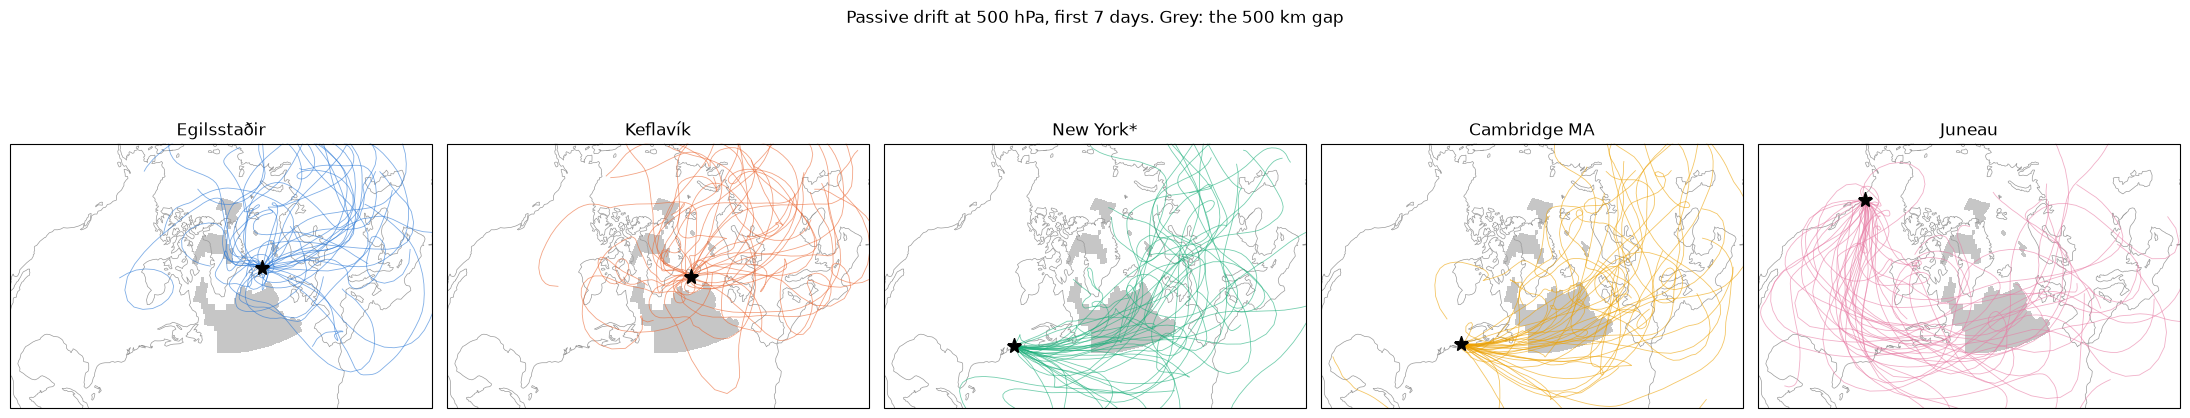

In [10]:
proj = ccrs.NorthPolarStereo(central_longitude=-45)
region_lats, region_lons = b.region_grid()
fig, axes = plt.subplots(1, 5, figsize=(22, 5), subplot_kw=dict(projection=proj))
for ax, site in zip(axes, SITES):
    # (a full -180..180 extent confuses cartopy's polar maps, so show 150W to 60E)
    ax.set_extent([-150, 60, 30, 90], crs=ccrs.PlateCarree())
    ax.pcolormesh(region_lons, region_lats, np.where(gap_masks[500], 1.0, np.nan),
                  transform=ccrs.PlateCarree(), cmap="Greys", vmin=0, vmax=3, shading="auto")
    ax.coastlines(color="#999999", lw=0.5)
    for winter in [WINTERS[0], WINTERS[-1]]:
        lats, lons, names = keep_tracks[(winter, 500)]
        idx = np.where(names == site)[0][::5]
        for i in idx:
            ax.plot(lons[:57, i], lats[:57, i], color=COLOURS[site], lw=0.6, alpha=0.6,
                    transform=ccrs.Geodetic())
    ax.plot(SITES[site][1], SITES[site][0], marker="*", color="black", ms=11,
            transform=ccrs.PlateCarree())
    ax.set_title(site)
plt.suptitle("Passive drift at 500 hPa, first 7 days. Grey: the 500 km gap", y=1.0)
plt.tight_layout(); plt.show()

## 8. Gap-hours per launch, by site (500 km gap)

Box: middle half of launches. Line in the box: median. Whiskers: 5th to 95th percentile. One panel per level.

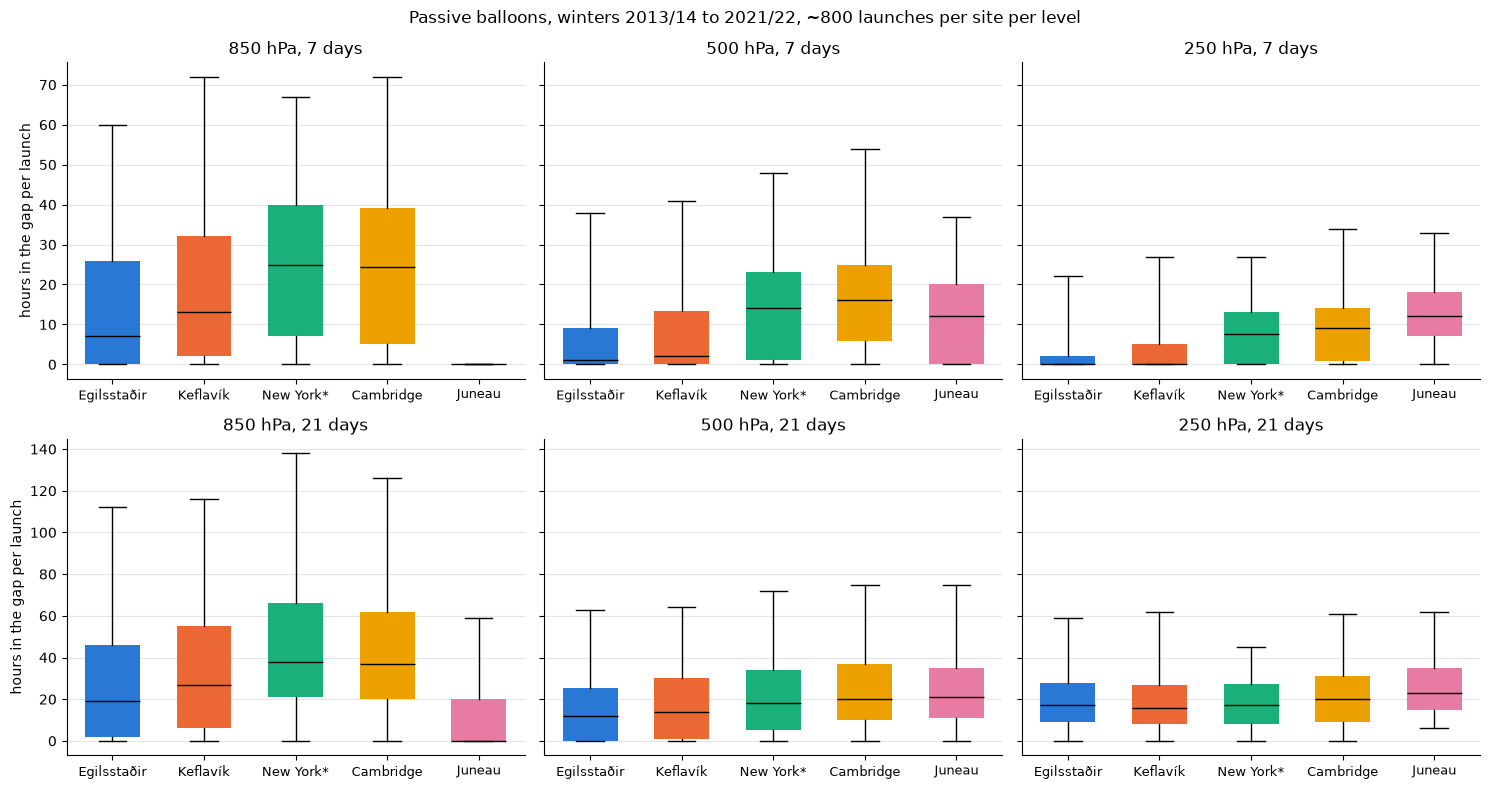

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
for r, (hname, col) in enumerate([("7 days", "gap_h_500km_7d"), ("21 days", "gap_h_500km_21d")]):
    for c, lev in enumerate(LEVELS):
        ax = axes[r, c]
        data = [runs.loc[(runs.level == lev) & (runs.site == s), col] for s in SITES]
        bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6,
                        medianprops=dict(color="black"))
        for patch, s in zip(bp["boxes"], SITES):
            patch.set_facecolor(COLOURS[s]); patch.set_edgecolor("none")
        ax.set_xticks(range(1, len(SITES) + 1), [s.replace(" MA", "") for s in SITES], fontsize=9)
        ax.set_title(f"{lev} hPa, {hname}")
        ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
        for side in ["top", "right"]: ax.spines[side].set_visible(False)
        if c == 0: ax.set_ylabel("hours in the gap per launch")
plt.suptitle("Passive balloons, winters 2013/14 to 2021/22, ~800 launches per site per level")
plt.tight_layout(); plt.show()

## What to read off this (Senan writes the findings)

Questions to answer in your own words once you've looked:
1. Which site gives the most gap-hours per launch at 7 days, and by how much over Cambridge or New York?
2. Does that change at 21 days? (US balloons have time to cross the Atlantic.)
3. Does the ranking hold at 300 and 800 km?
4. How quickly does each site's balloon first enter the gap?